# EcoFOCIpy ADCP QC - 17CB-1A

- mostly remove >200 cm/s flows in u/v


In [6]:
import xarray as xa
import numpy as np

import matplotlib.pyplot as plt

from EcoFOCIpy.plots import TimeSeriesStickPlot

In [7]:
xdf = xa.load_dataset('17cb1a_0174m.trimmed.nc')

In [8]:
len(xdf.depth)

24

/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:119: UserWarning: set_ticklabels() shoul

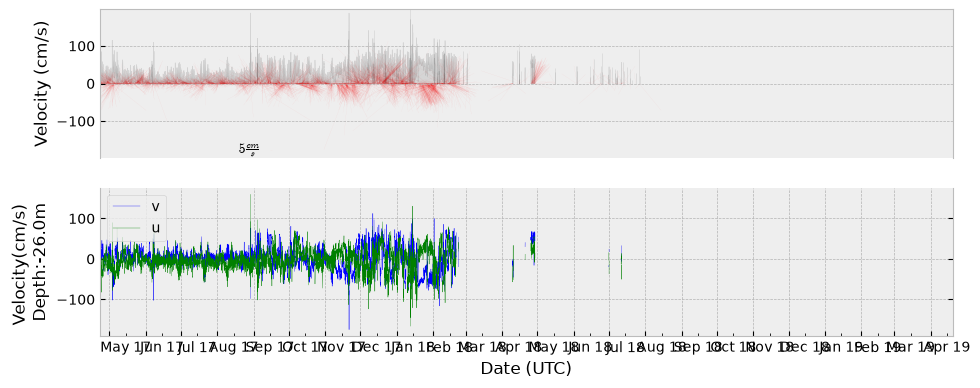

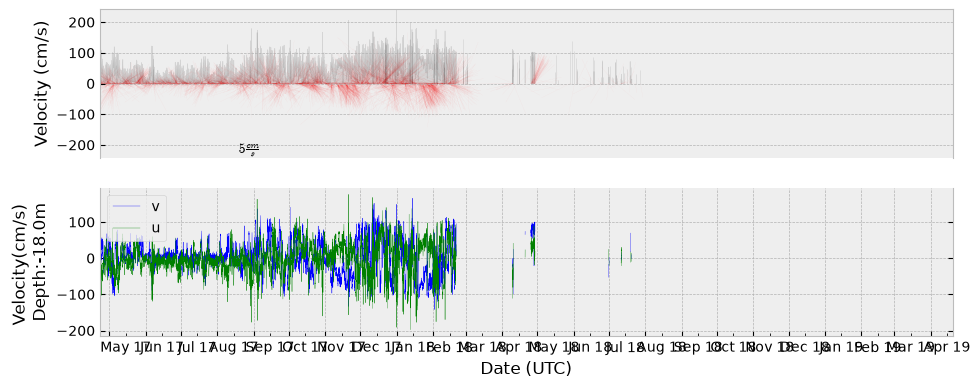

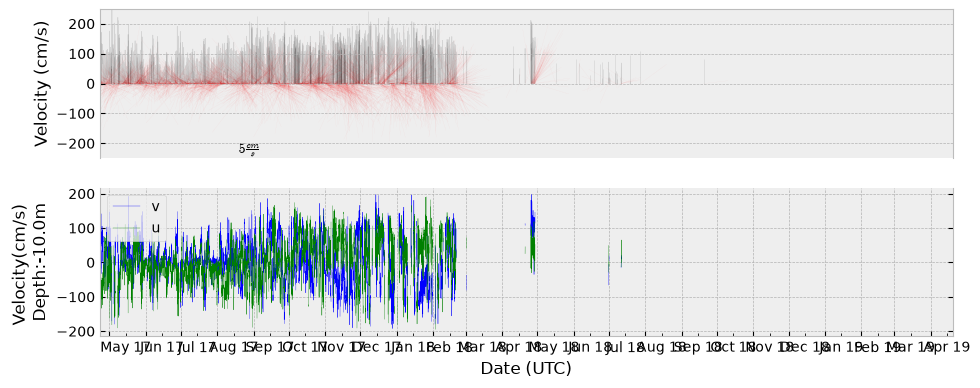

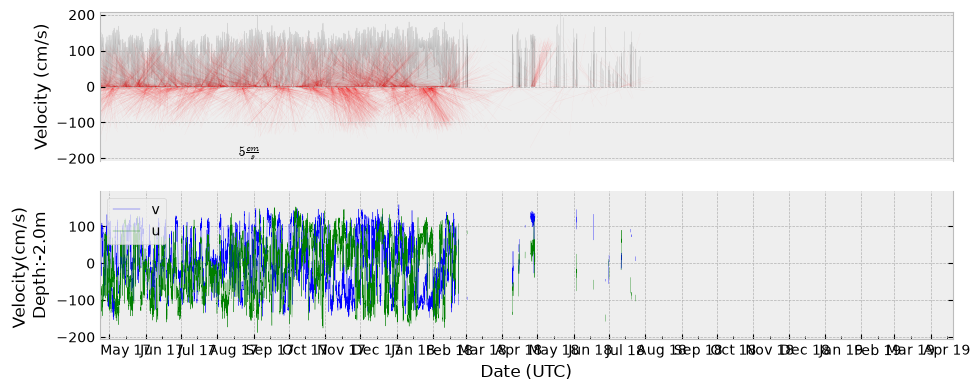

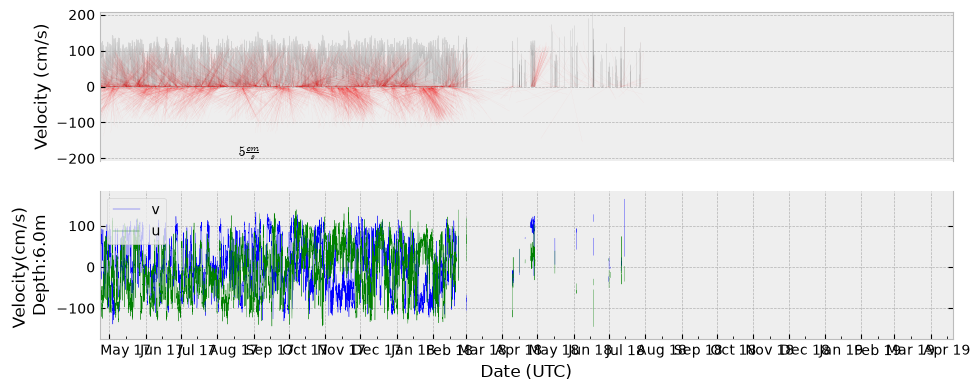

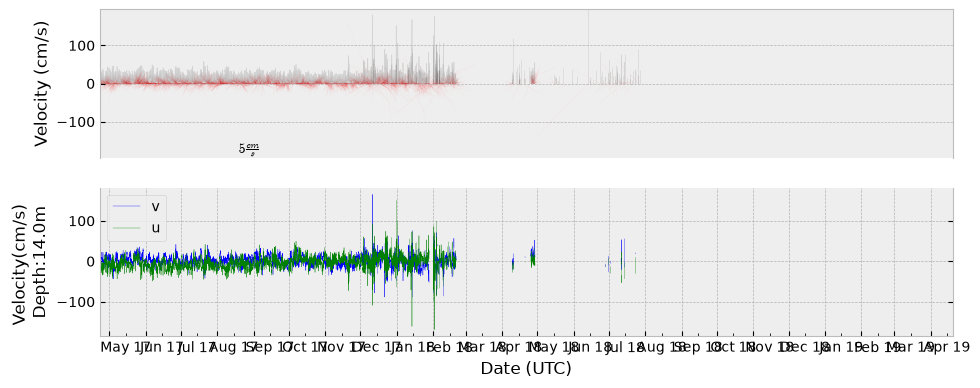

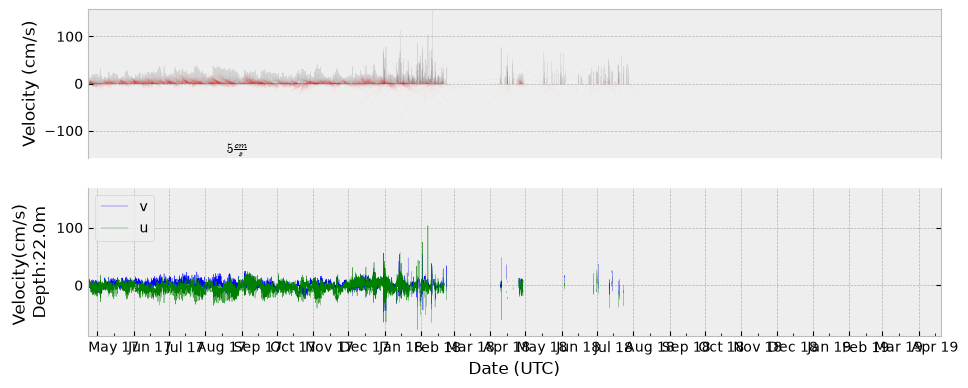

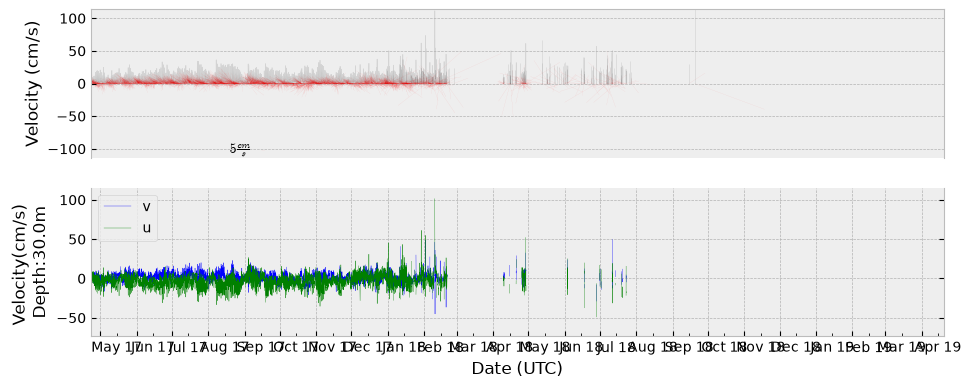

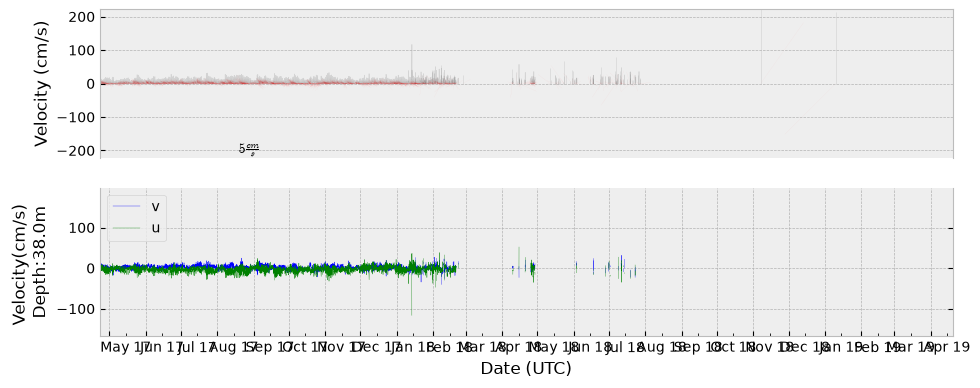

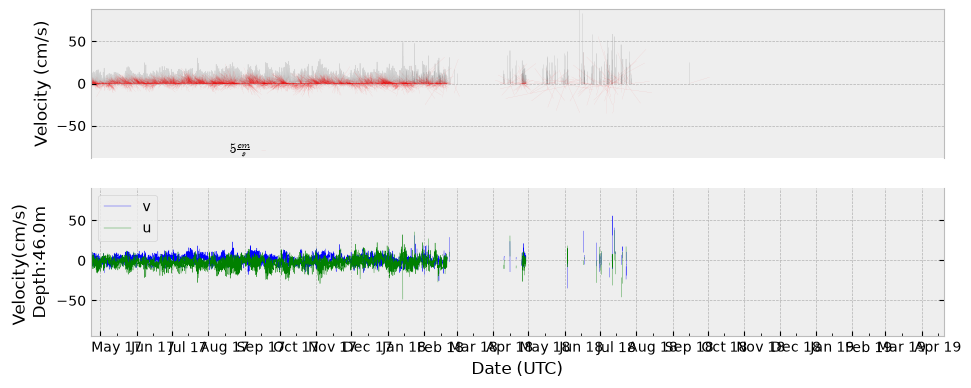

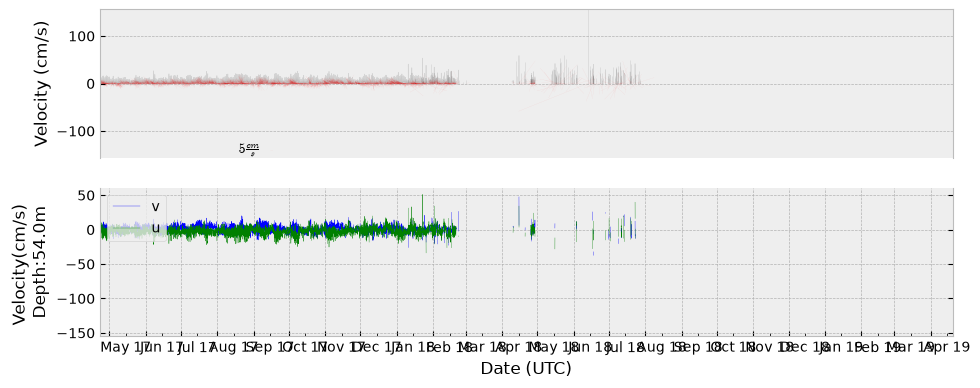

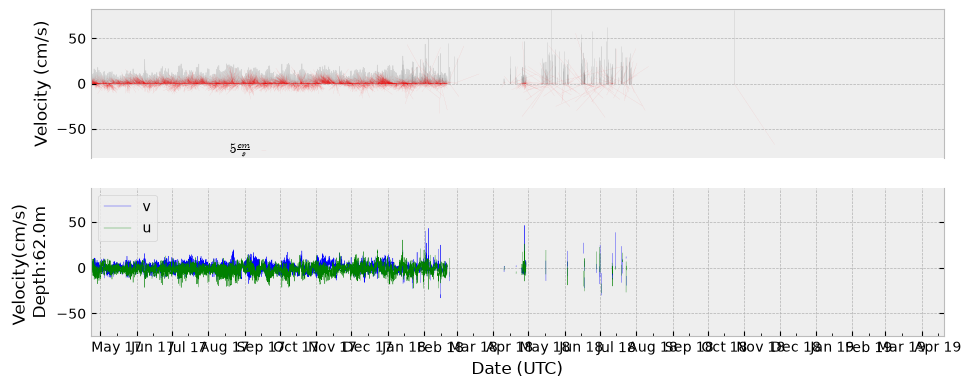

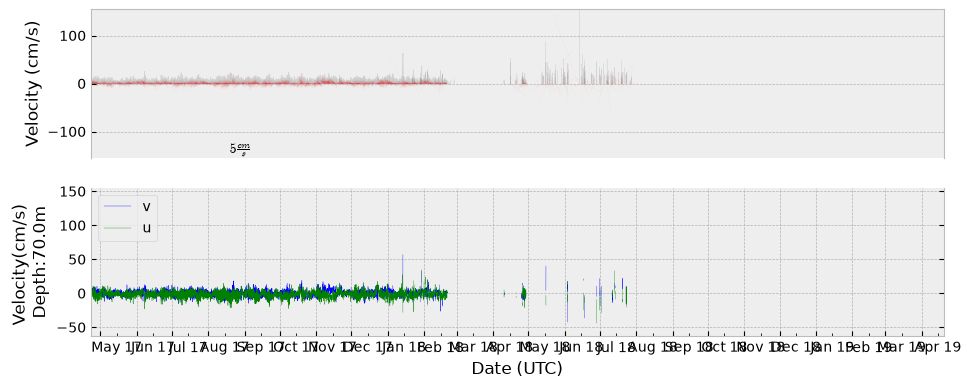

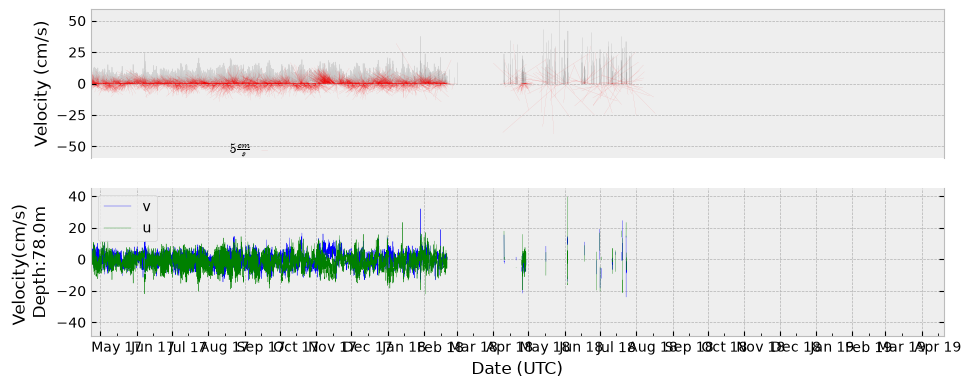

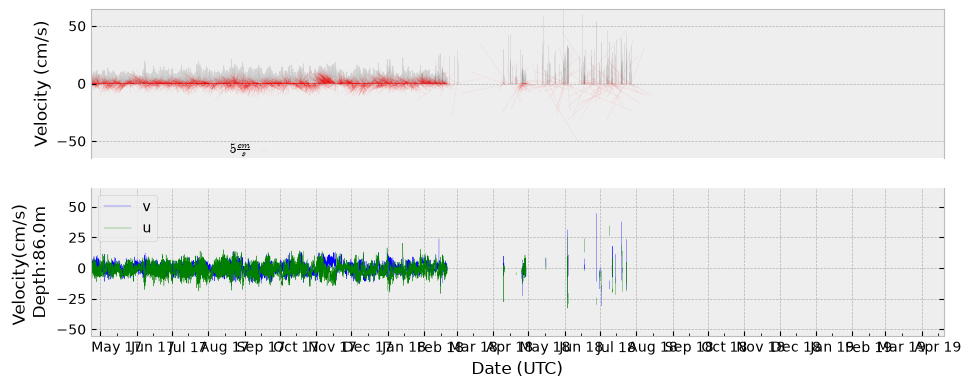

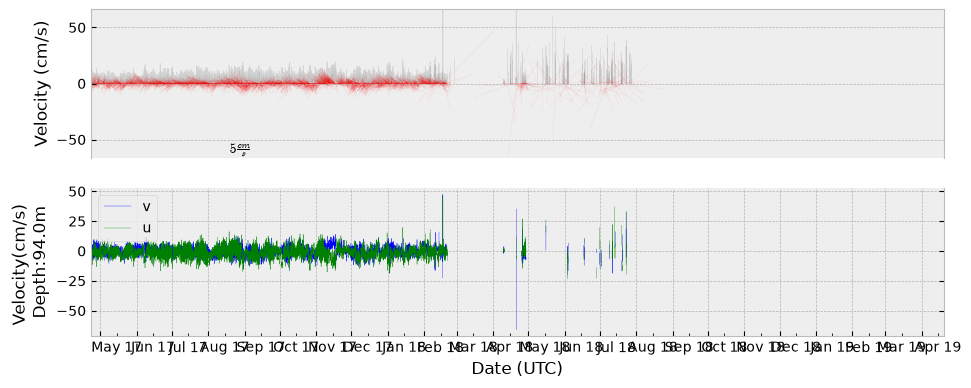

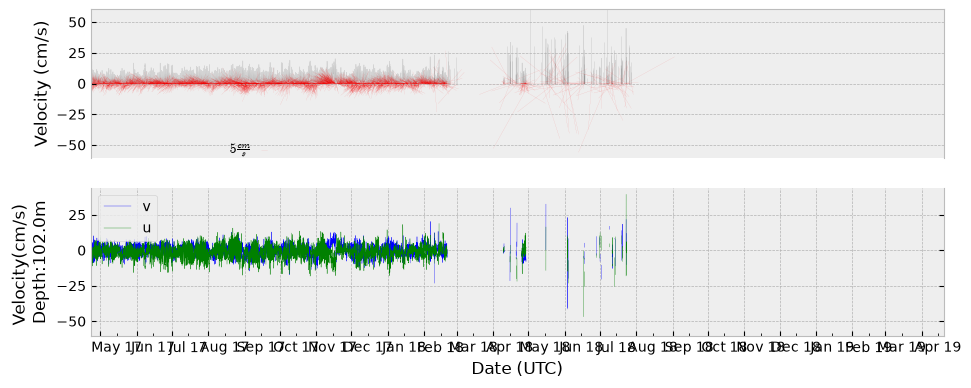

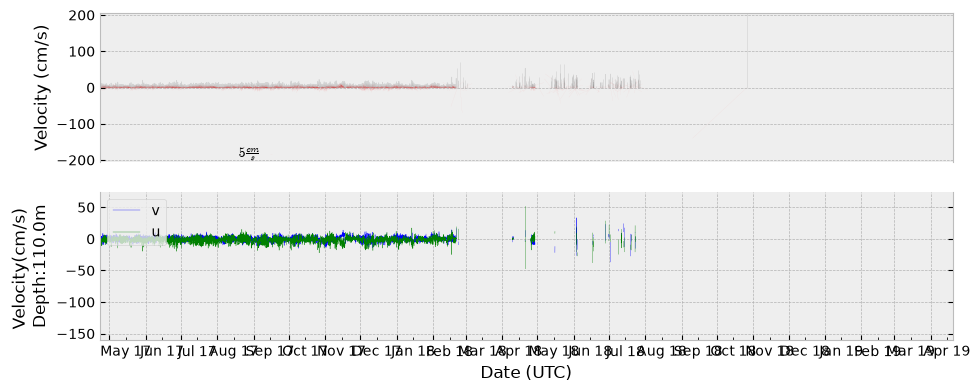

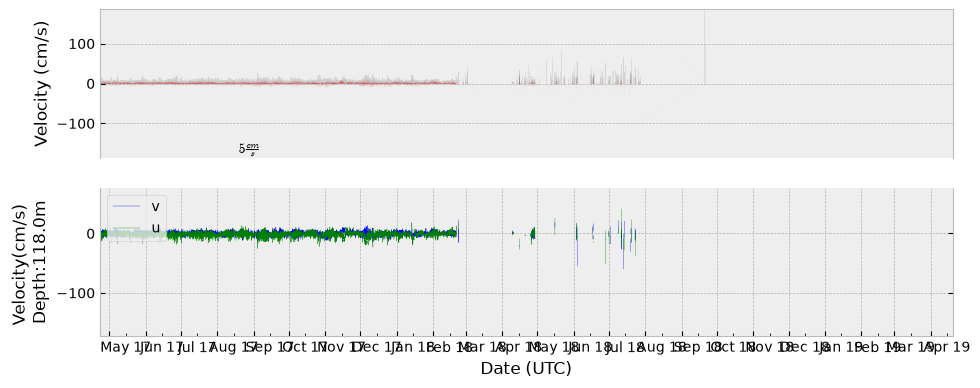

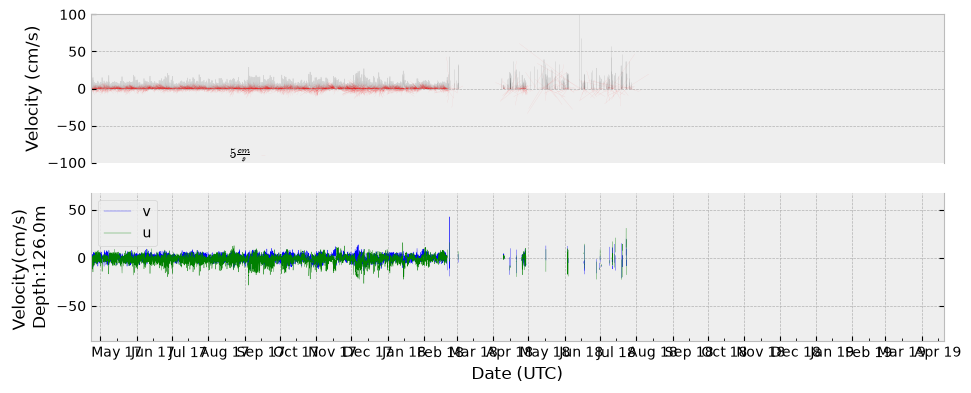

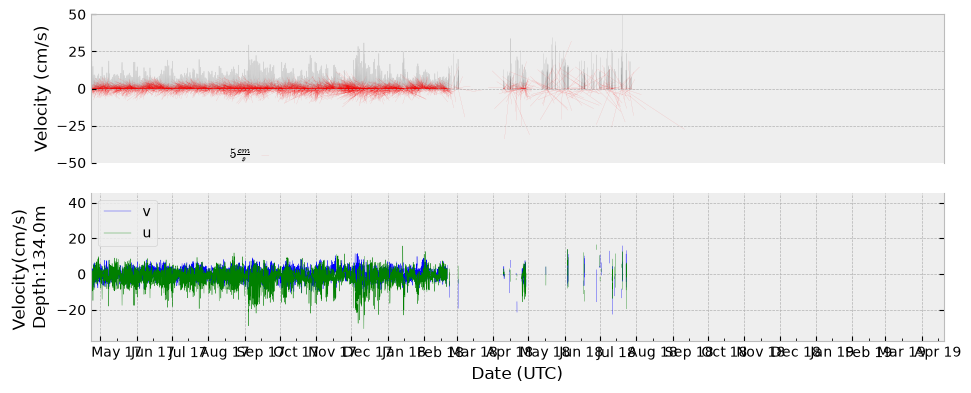

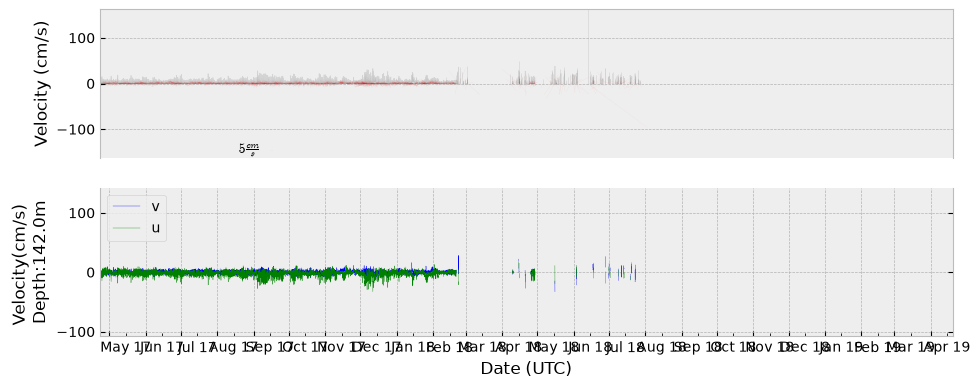

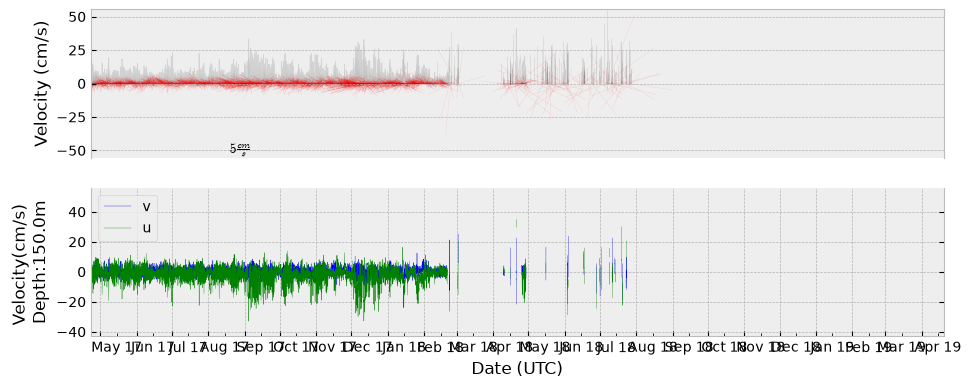

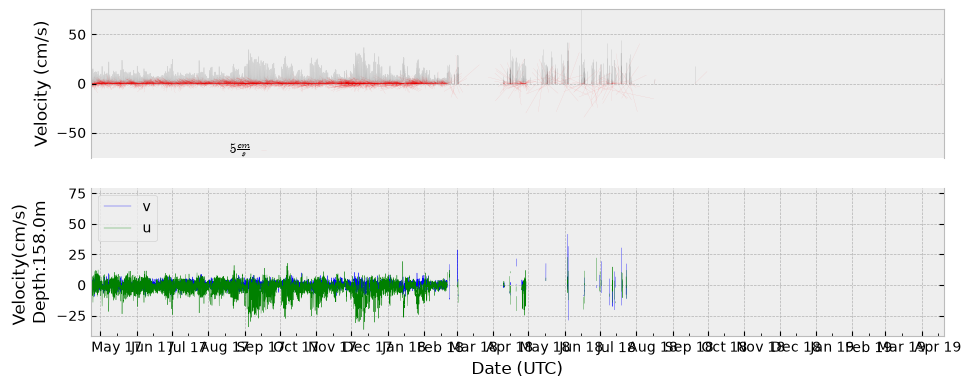

In [13]:
for i in range(0,len(xdf.depth),1):
    try:
        p1 = TimeSeriesStickPlot.Timeseries1dStickPlot()
        plt1, fig1 = p1.plot(timedata=xdf.time, 
                         udata=xdf.isel(depth=i,latitude=0,longitude=0).u_curr_comp, 
                         vdata=xdf.isel(depth=i,latitude=0,longitude=0).v_curr_comp,
                         rotate=0,
                         ylabel = f'Velocity(cm/s) \n {xdf.isel(depth=i).depth.values}m ')
        plt1.ylabel(f'Velocity(cm/s) \n Depth:{xdf.isel(depth=i).depth.values}m ')
    except:
        pass

In [12]:
xdf =xdf.where(np.abs(xdf.u_curr_comp) <=200,np.nan)
xdf =xdf.where(np.abs(xdf.v_curr_comp) <=200,np.nan)
xdf

<xarray.Dataset> Size: 27MB
Dimensions:          (latitude: 1, longitude: 1, time: 17441, depth: 24)
Coordinates:
  * latitude         (latitude) float64 8B 57.72
  * longitude        (longitude) float64 8B -152.3
  * time             (time) datetime64[ns] 140kB 2017-04-23T04:00:00 ... 2019...
  * depth            (depth) float64 192B -26.0 -18.0 -10.0 ... 150.0 158.0
Data variables:
    u_curr_comp      (latitude, longitude, time, depth) float64 3MB -8.448 .....
    v_curr_comp      (latitude, longitude, time, depth) float64 3MB -6.73 ......
    w_curr_comp      (latitude, longitude, time, depth) float64 3MB 2.6 ... nan
    w_curr_comp_err  (latitude, longitude, time, depth) float64 3MB 3.4 ... nan
    agc1             (latitude, longitude, time, depth) float64 3MB 78.0 ... nan
    agc2             (latitude, longitude, time, depth) float64 3MB 85.0 ... nan
    agc3             (latitude, longitude, time, depth) float64 3MB 83.0 ... nan
    agc4             (latitude, longitude, time, depth) float64 3MB 82.0 ... nan
Attributes: (12/13)
    Latitude_DegMMddW:                      57 43.310 N
    Longitude_DegMMddN:                     152 17.430 W
    MooringID:                              17CB-1A
    platform_deployment_date:               2017-04-23T03:26:00Z
    platform_deployment_cruise_name:        DY1704
    platform_recovery_date:                 2019-04-19T20:00:00Z
    ...                                     ...
    platform_deployment_recovery_comments:  1/2m chain section adde below 30"...
    WaterDepth:                             193.0
    date_created:                           2026-09-17T14:25:14Z
    date_modified:                          
    QC_indicator:                           unknown
    history:                                Trimmed to deployment.

In [14]:
# xdf['history'] = xdf.history + 'QC of high u/v values'

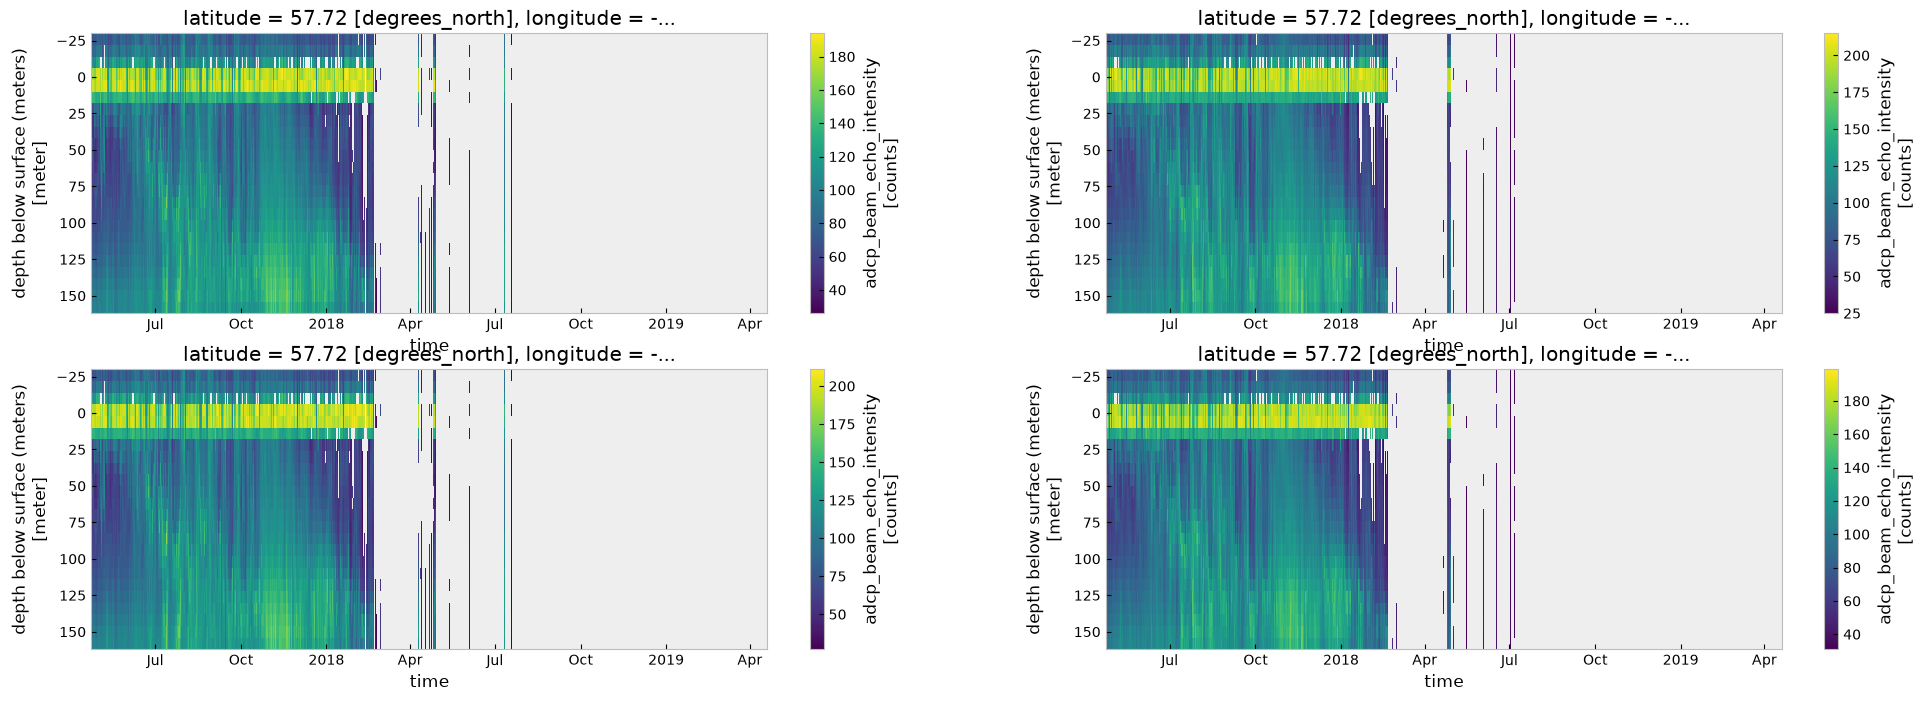

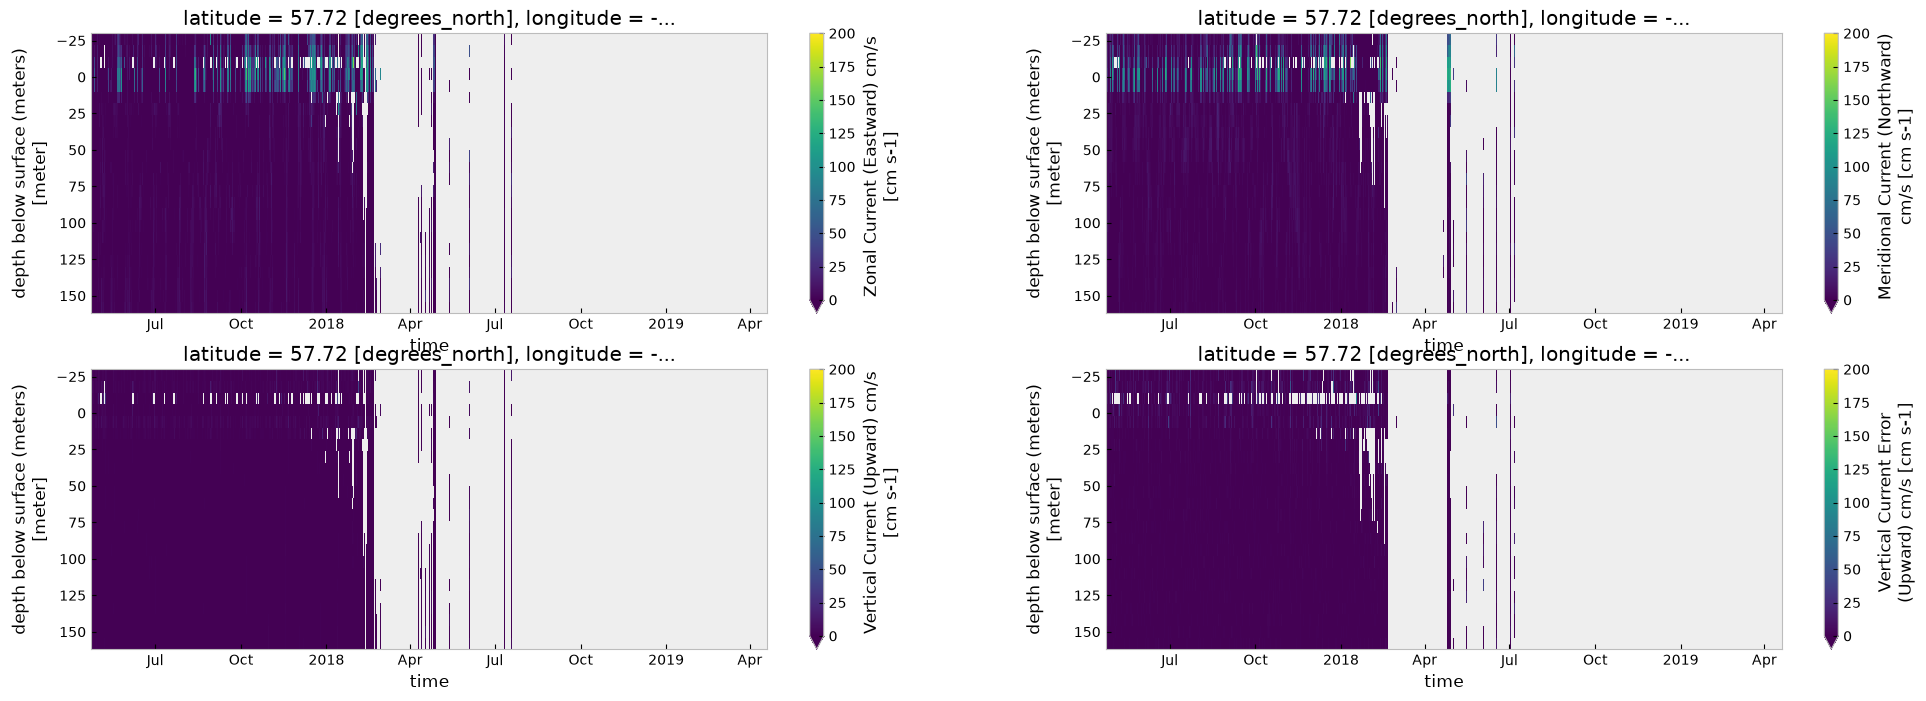

In [15]:
#optional plotting

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    xdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    xdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    xdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    xdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [16]:
try:
    xdf.attrs['history'] = xdf.attrs['history']+'  removed U,V >2000cm/s'
except:
    xdf.attrs['history'] = '  removed U,V >200cm/s'    

## Trim above surface (negative values)

In [17]:
ixdf = xdf.where(xdf.depth >=-0.).dropna(how='all',dim='depth')

In [18]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  trimmed above surface'

In [19]:
ixdf.to_netcdf('17cb1a_0174m.trimmed.nc')

In [20]:
xdf = xa.load_dataset('17cb1a_0174m.trimmed.nc')

In [21]:
ixdf = xdf.interpolate_na(dim='time',max_gap='2H')

## Interpolate over singleton missing gaps linearly

In [22]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 1hour gaps'

In [23]:
ixdf = ixdf.interpolate_na(dim='depth',max_gap=3)

In [24]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 2 vertical bin'

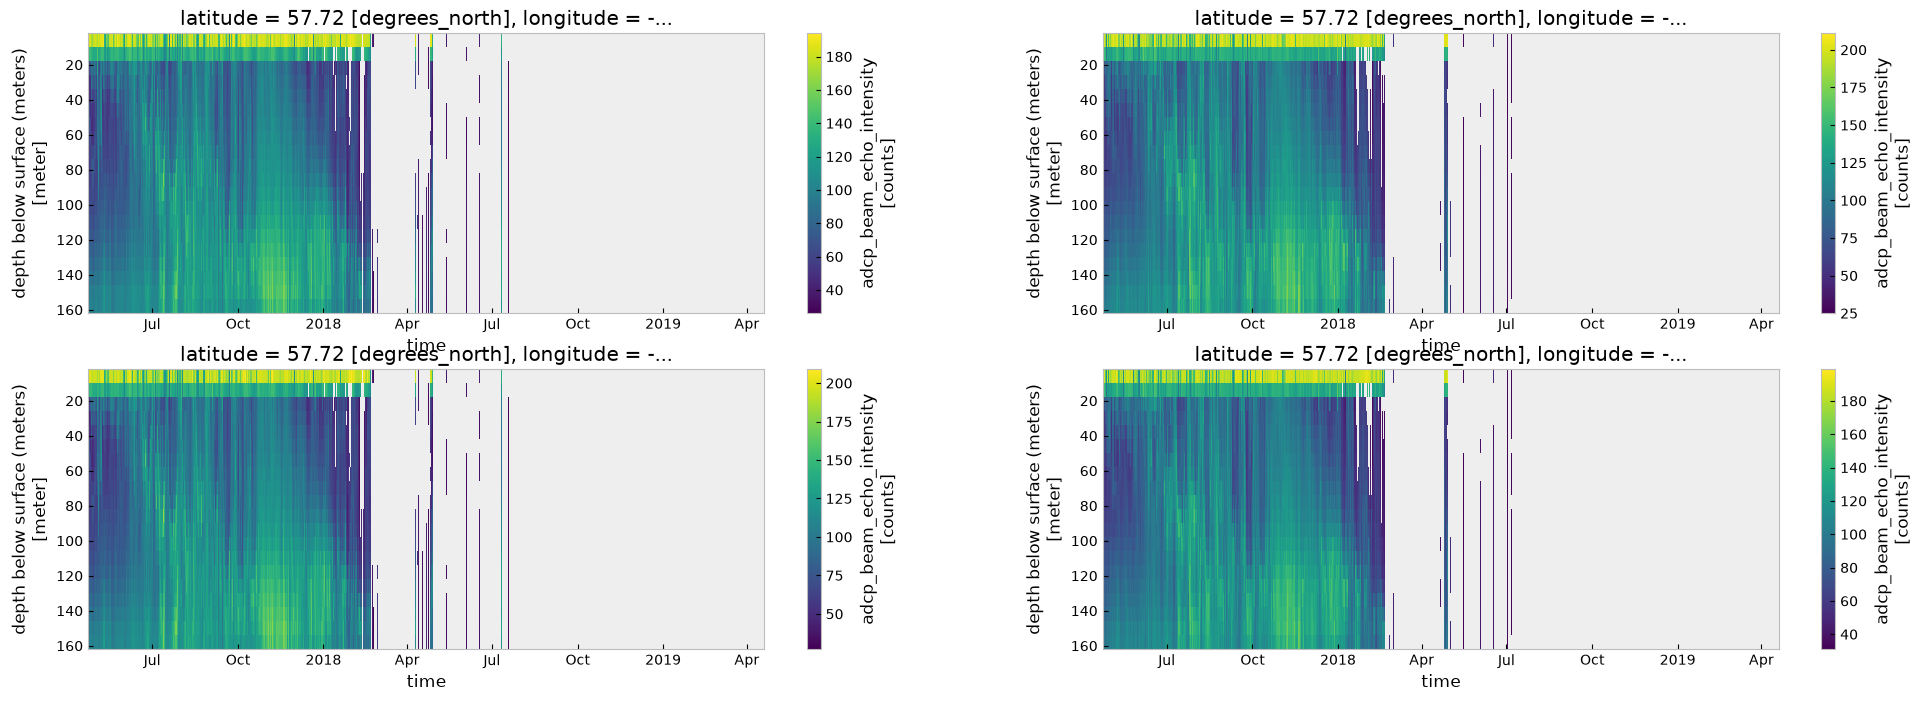

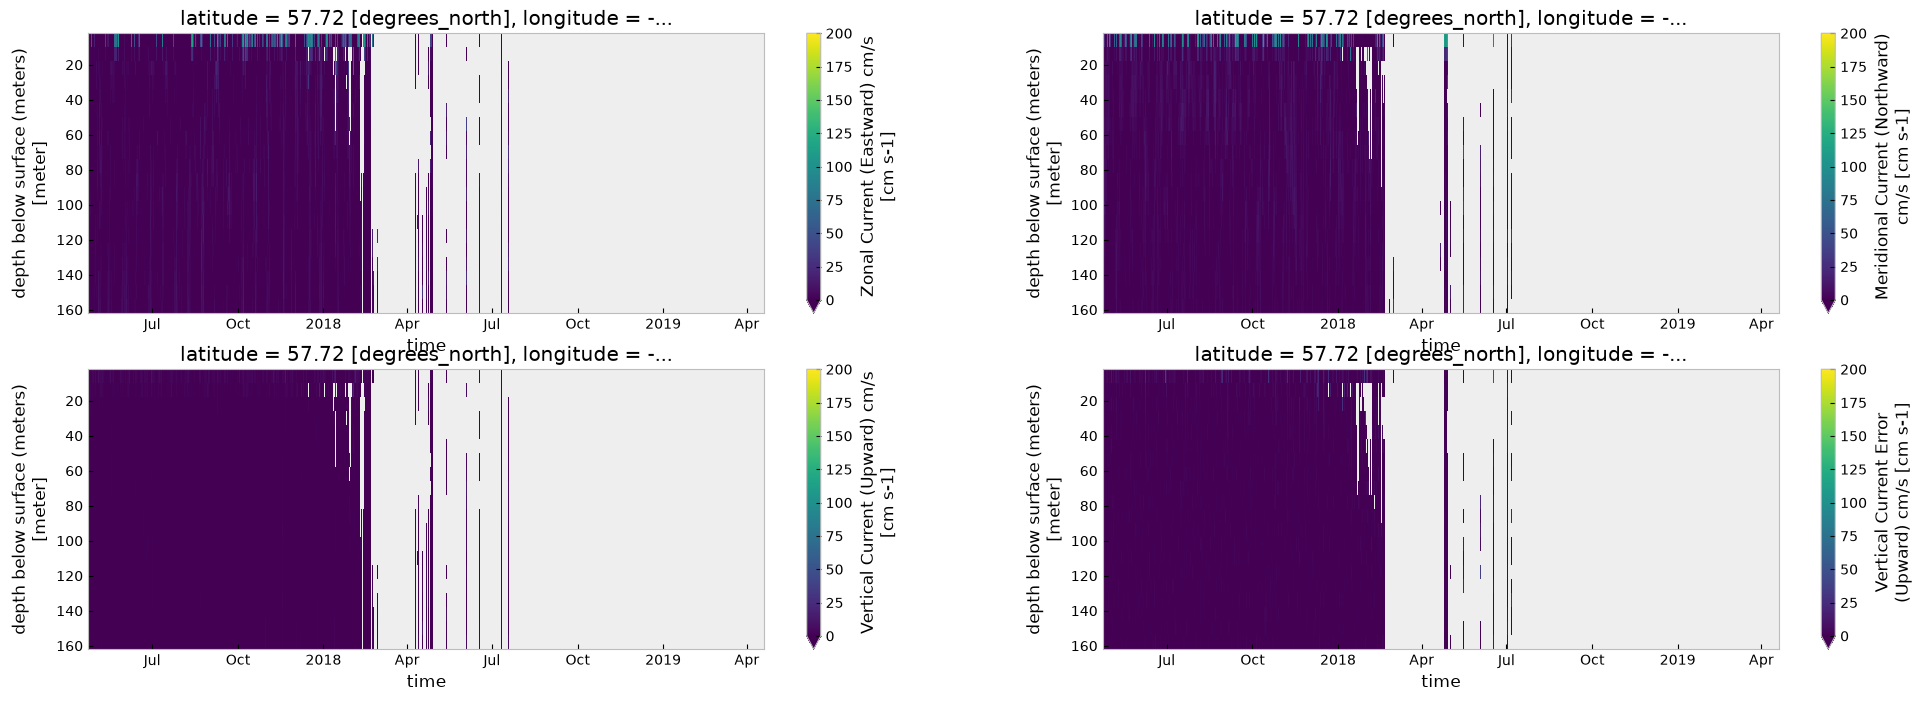

In [25]:

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    ixdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    ixdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    ixdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    ixdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [26]:
ixdf.to_netcdf('17cb1a_0174m.filtered.nc')

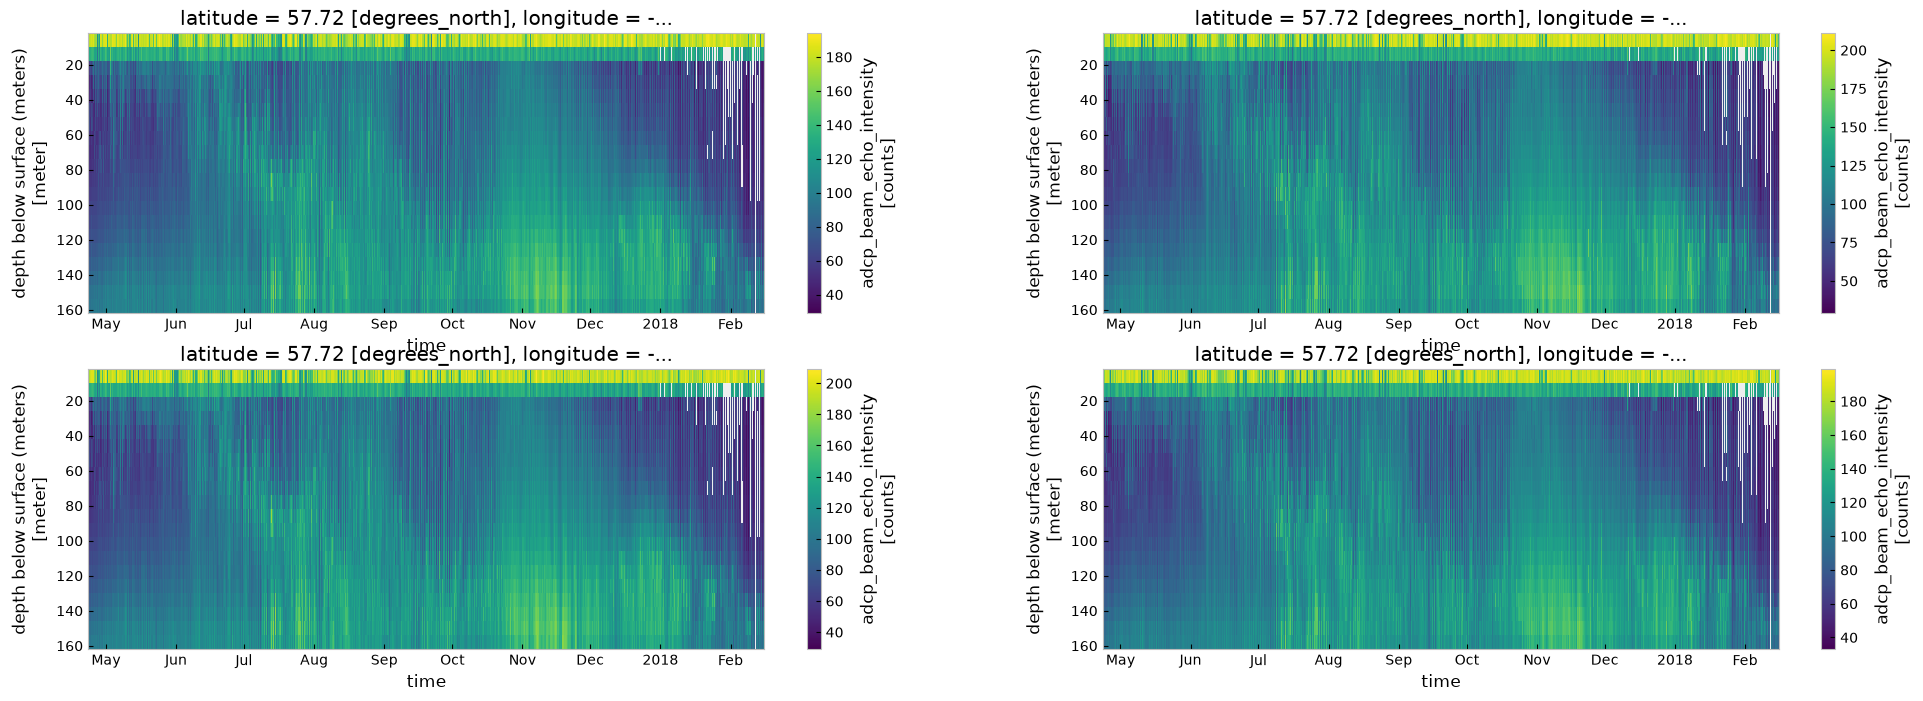

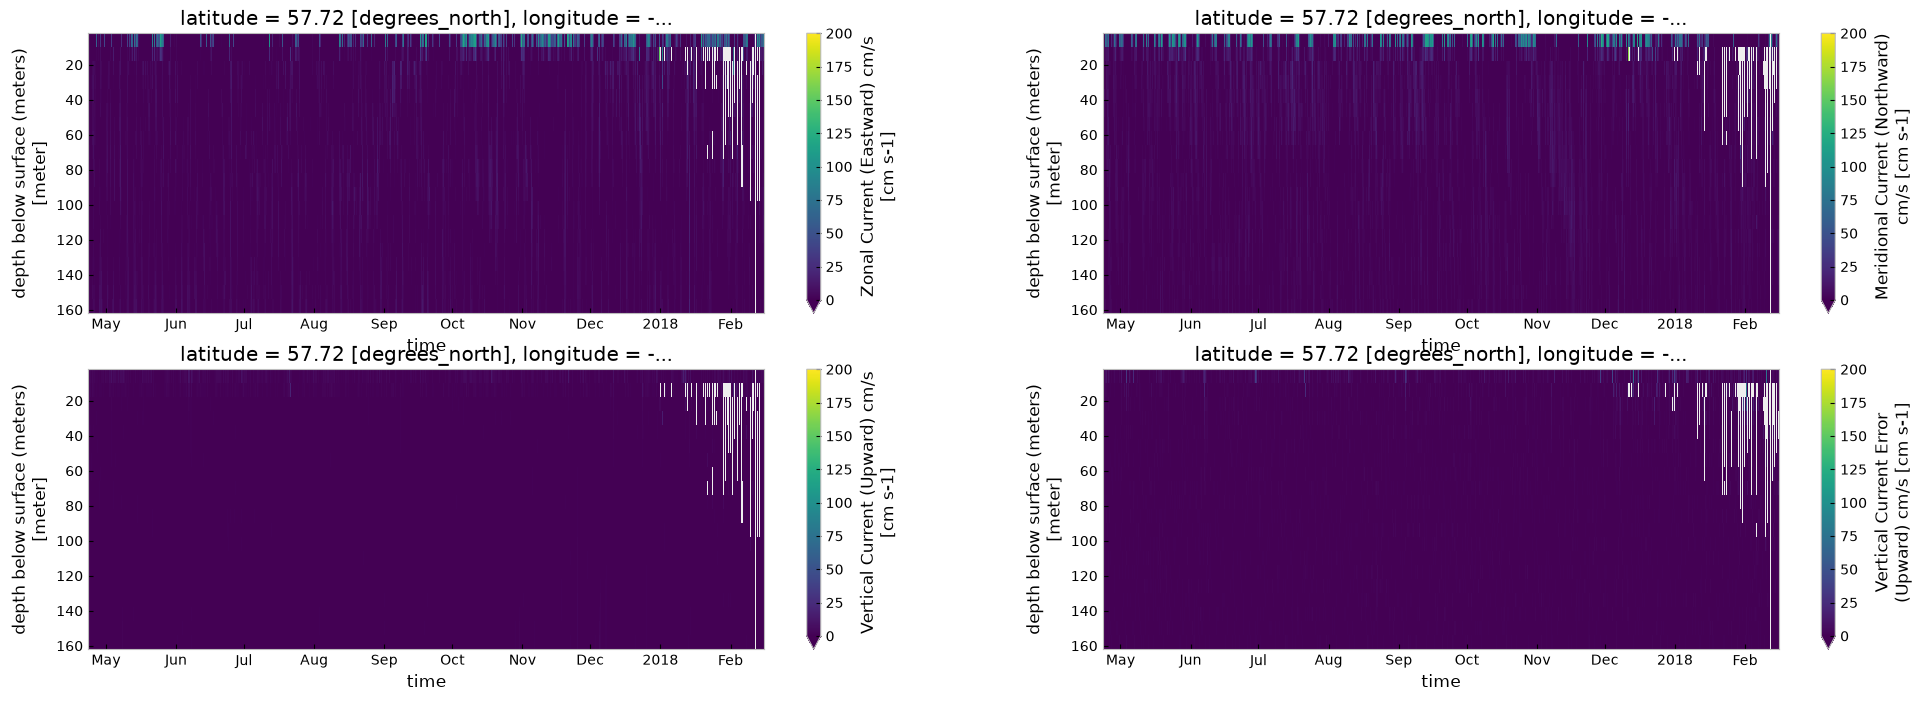

In [28]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    ixdf.sel(time=slice('2017-01-01','2018-02-15'))['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [27]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  trimmed to good data'
ixdf.sel(time=slice('2017-01-01','2018-02-15')).to_netcdf('17cb1a_0174m.filtered.trimmed.nc')

In [ ]:
ixdf.sel(time=slice('2017-01-01','2018-02-15'))